In [ ]:
# %pip install isotree
# %pip install pyod
# %pip install combo
# %pip install tqdm
# %pip install umap-learn
# %pip install pcmap

In [ ]:
# Librerie
import pandas as pd
import numpy as np
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.decomposition import PCA

# High Dimensionality
from pyod.models.abod import ABOD

# Elliptic
from sklearn.covariance import EllipticEnvelope

# RKNN
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)

# Ensemble
from pyod.models.feature_bagging import FeatureBagging
# carico LOF per FeaBag, chiaramente si può cambiare a seconda del modello semplice scelto
from pyod.models.lof import LOF
from pyod.models.loda import LODA

# Foreste
from sklearn.ensemble import IsolationForest
from isotree import IsolationForest as EIF

# Grafici
import matplotlib.pyplot as plt
import seaborn as sns

# Proiezioni
from sklearn.manifold import MDS
from sklearn.manifold import TSNE
import pacmap
import umap

In [ ]:
# Dati
df = pd.read_csv("cmi_internet.csv")

train = pd.read_csv("train_imputed.csv")
test = pd.read_csv("test_imputed.csv")

tt = np.concatenate([train, test], axis=0)
df_unito = pd.DataFrame(tt, columns=train.columns)

In [ ]:
# Scalers

standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

X = df_unito.values
y = np.array(df_unito['sii'])
X_standard = standard_scaler.fit_transform(X)
y = y.astype(int)

X_train, X_test, _, _ = train_test_split(
    X_standard, y, test_size=0.3, random_state=0)

In [ ]:
####
# High Dimensionality
####

In [ ]:
# Fast ABOD

#!!! LENTO, su portatile in carica ci mette 5+ minuti; sul fisso un paio

# Contamination è la proporzione di outliers; n_neighbors autoesplicativo
abod_model = ABOD(contamination=0.01, n_neighbors=76, n_jobs=-1)
abod_model.fit(X_train)

# 0 = inliers e 1 = outliers
abod_preds = abod_model.predict(X_train)
abod_scores = abod_model.decision_scores_

In [ ]:
####
# Ensemble
####

In [ ]:
# FeaBag

feabag_model = FeatureBagging(
    base_estimator=LOF(),  # stimatore base, si può cambiare
    n_estimators=100,  # da testare coi dati veri per capire quanto ci vuole
    max_features=0.5,  # proporzione di variabili da estrarre per ogni modello
    contamination=0.01,  # come prima, 1% di outliers
    random_state=222,
    n_jobs=-1
)
feabag_model.fit(X_train)

feabag_preds = feabag_model.predict(X_train)

In [ ]:
'''# LODA

# n_bins si lascia ottimizzare al modello; n_random_cuts è praticamente il numero di vettori generati
loda_model = LODA(contamination=0.01, n_bins='auto', n_random_cuts=100)
loda_model.fit(train)

loda_preds = loda_model.predict(train)'''

In [ ]:
####
# Foreste
####

In [ ]:
'''# Random Forest

isolation_forest_model = IsolationForest(
    n_estimators=100,  # da testare coi dati veri per capire quanto ci vuole, NUMERO di alberi
    # dimensione del campione per ogni albero, sembra che 256 abbia base scientifica
    max_samples=256,
    contamination=0.01,  # usual
    random_state=222
)
isolation_forest_preds = isolation_forest_model.fit_predict(train)'''

In [ ]:
# Extended Forest


# In isotree, ndim=1 equivale a Isolation Forest standard.
# Scegliere ndim=df.shape[1] per la Extended Isolation Forest completa.
extended_forest_model = EIF(
    sample_size=256,  # come prima
    ntrees=100,  # numero alberi
    # serve a dire al modello che vogliamo la versione estesa
    ndim=train.shape[1],
    random_seed=222,
    n_jobs=-1
)
extended_forest_model.fit(X_train)

# EIF genera uno score (più alto = più probabile outlier)
extended_forest_scores = extended_forest_model.predict(X_train)

# gli outlier vanno trovati a mano
threshold = np.percentile(extended_forest_scores, 99)  # 99 percentile
extended_forest_preds = (extended_forest_scores > threshold).astype(int)

In [ ]:
# Distanza: RKNN
# 1. Trova i k-vicini per ogni punto
k = 76
nbrs = NearestNeighbors(n_neighbors=k, n_jobs=-1).fit(X_train)
distances, indices = nbrs.kneighbors(X_train)

# 2. Conta quante volte ogni indice compare nella matrice dei vicini
# 'indices' contiene gli indici dei k vicini per ogni riga
flat_indices = indices.flatten()
counts = np.bincount(flat_indices, minlength=len(X_train))

# 3. Lo score RkNN è il conteggio (invertito)
# Più il conteggio è basso, più il punto è un outlier
rknn_scores = counts

out = np.percentile(rknn_scores, q=1)

outliers_rknn = np.zeros(len(rknn_scores))
outliers_rknn[rknn_scores <= out] = 1

plt.hist(rknn_scores, bins=range(int(np.max(rknn_scores))))
# plt.axvline(np.max(rknn_scores[np.where(out == 1)]), c='k', linestyle='--')
plt.show()

n_outliers_rknn = np.sum(outliers_rknn)
print(
    f"Numero di outlier trovati: {int(n_outliers_rknn)} ({n_outliers_rknn/len(df_unito)*100:.2f}%)")

In [ ]:
%%time
# Deviation-based Approaches: EllEnv

ellenv = EllipticEnvelope(random_state=222, contamination=0.01)
ellenv.fit(X_train)

# predict returns 1 for an inlier and -1 for an outlier
outliers_ellenv = ellenv.predict(X_train)

# print (outliers_ellenv)
n_outliers_ellenv = np.sum(outliers_ellenv == -1)
print(
    f"Numero di outlier trovati: {int(n_outliers_ellenv)} ({n_outliers_ellenv/len(df_unito)*100:.2f}%)")

In [ ]:
# Dataset Outliers
df_outliers = pd.DataFrame(
    np.column_stack((outliers_rknn, outliers_ellenv,
                    feabag_preds, extended_forest_preds, abod_preds)),
    columns=['rknn', 'ellenv', 'feabag', 'ext_forest', 'abod']
)
df_outliers['risultati'] = (
    (df_outliers['rknn'] == 1).astype(int) +
    (df_outliers['ellenv'] == -1).astype(int) +
    (df_outliers['feabag'] == 1).astype(int) +
    (df_outliers['ext_forest'] == 1).astype(int) +
    (df_outliers['abod'] == 1).astype(int)
)

df_outliers["colore"] = np.where(df_outliers["risultati"] >= 2, 1, 0)
# volendo aumentare a 2% per maggioranza

In [ ]:
'''df_outliers = pd.read_csv("df_outliers.csv")
df_outliers["colore"] = np.where(df_outliers["risultati"] >= 2, 1, 0)'''

In [ ]:
df_intero_out = df_unito.copy()
df_intero_out["outlier"] = df_outliers["colore"]
df_solo_out = df_intero_out[df_intero_out["outlier"] == 1]

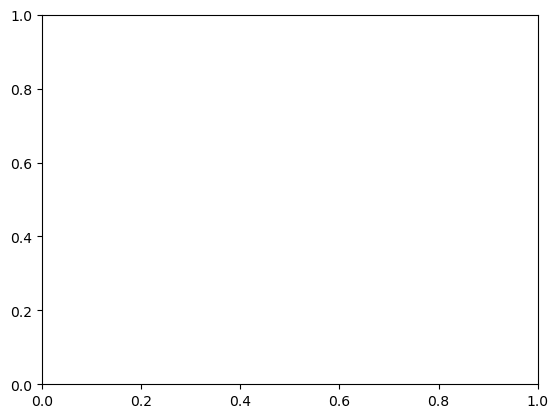

In [50]:
# VISUALIZZAZIONE OUTLIERS
fig, ax = plt.subplots()

In [51]:
%%time
#T-sne
tsne = TSNE(n_components=3, n_jobs = -1)
df_unito_tsne = tsne.fit_transform(X_train)

CPU times: total: 11min 34s
Wall time: 1min 46s


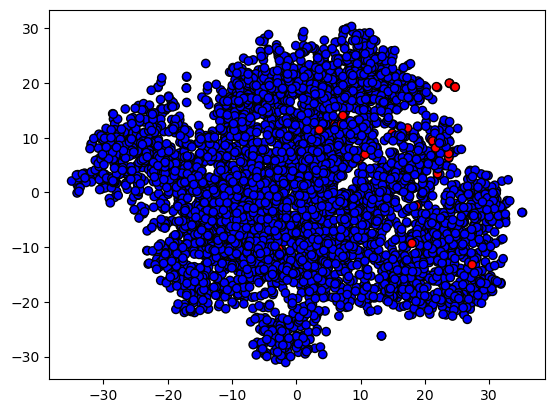

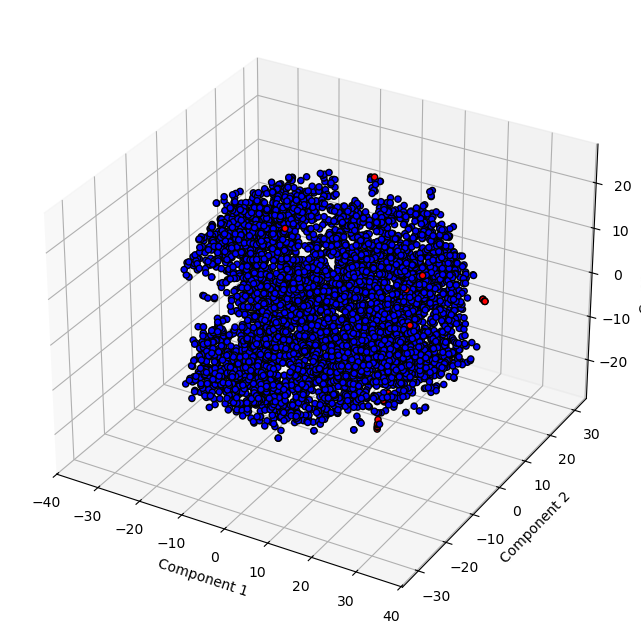

In [52]:
# 2D
plt.scatter(df_unito_tsne[:, 0], df_unito_tsne[:, 1],
            c=df_outliers['colore'], cmap=plt.cm.bwr, edgecolor='k', alpha=1)

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')

plt.show()

# 3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(df_unito_tsne[:, 0],
           df_unito_tsne[:, 1],
           df_unito_tsne[:, 2],
           c=df_outliers['colore'],
           cmap=plt.cm.bwr,
           edgecolor='k',
           alpha=1)

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')
ax.set_zlabel('Component 3')

plt.show()

In [53]:
%%time
#PCA
pca = PCA(n_components=3, random_state=222)
df_unito_pca = pca.fit_transform(X_train)

CPU times: total: 46.9 ms
Wall time: 19.9 ms


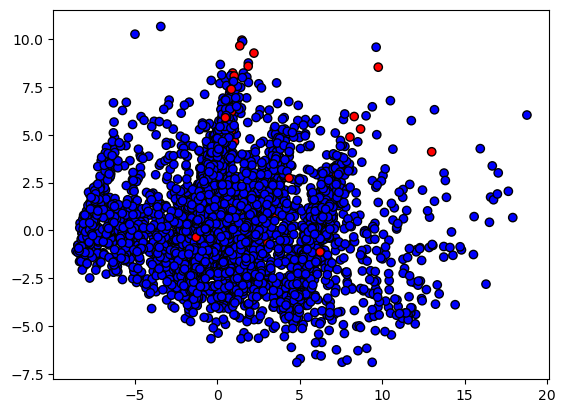

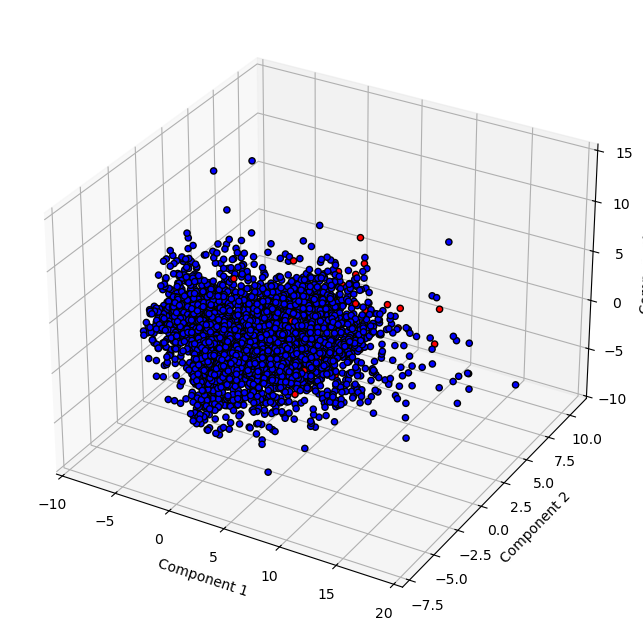

In [54]:
# 2D
plt.scatter(df_unito_pca[:, 0], df_unito_pca[:, 1],
            c=df_outliers['colore'], cmap=plt.cm.bwr, edgecolor='k', alpha=1)

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')

plt.show()

# 3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(df_unito_pca[:, 0],
           df_unito_pca[:, 1],
           df_unito_pca[:, 2],
           c=df_outliers['colore'],
           cmap=plt.cm.bwr,
           edgecolor='k',
           alpha=1)

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')
ax.set_zlabel('Component 3')

plt.show()

In [55]:
%%time
# PaCMAP

paCMAP = pacmap.PaCMAP(n_components=3, n_neighbors=None, MN_ratio=0.5, FP_ratio=2.0, random_state = 222)
df_unito_pacmap = paCMAP.fit_transform(X_train)

Note: `n_components != 2` have not been thoroughly tested.


CPU times: total: 6 s
Wall time: 3.77 s


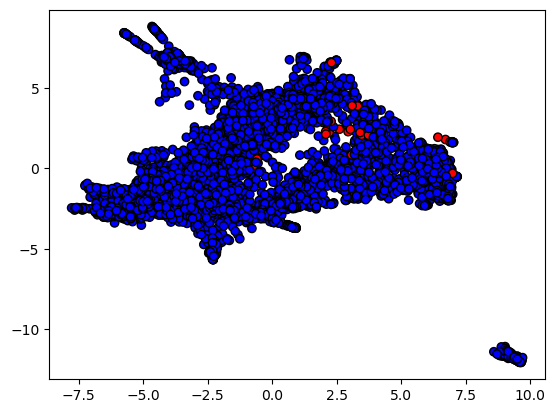

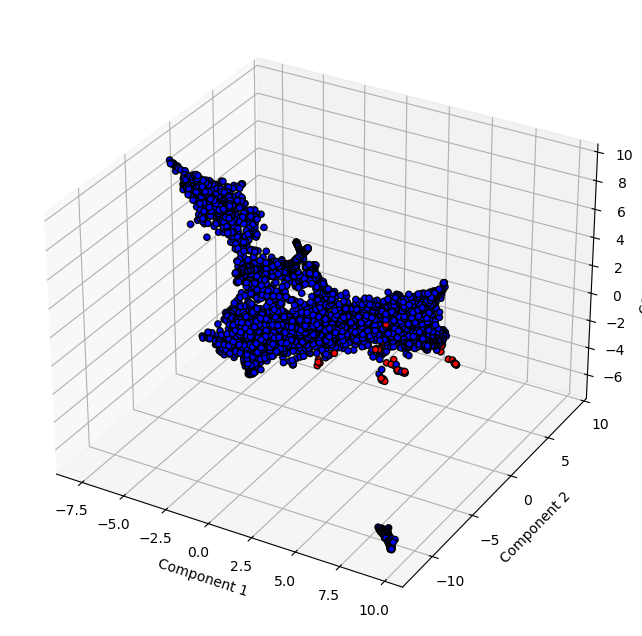

In [56]:
# 2D
plt.scatter(df_unito_pacmap[:, 0], df_unito_pacmap[:, 1],
            c=df_outliers['colore'], cmap=plt.cm.bwr, edgecolor='k', alpha=1)

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')

plt.show()

# 3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(df_unito_pacmap[:, 0],
           df_unito_pacmap[:, 1],
           df_unito_pacmap[:, 2],
           c=df_outliers['colore'],
           cmap=plt.cm.bwr,
           edgecolor='k',
           alpha=1)

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')
ax.set_zlabel('Component 3')

plt.show()

In [57]:
%%time
#UMAP
umappe = umap.UMAP(n_components = 3, random_state = 222)
df_unito_umap = umappe.fit_transform(X_train)

c:\Users\Riccardo\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


CPU times: total: 1min 43s
Wall time: 1min 46s


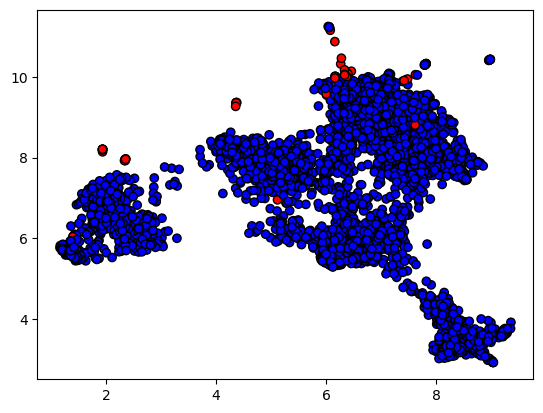

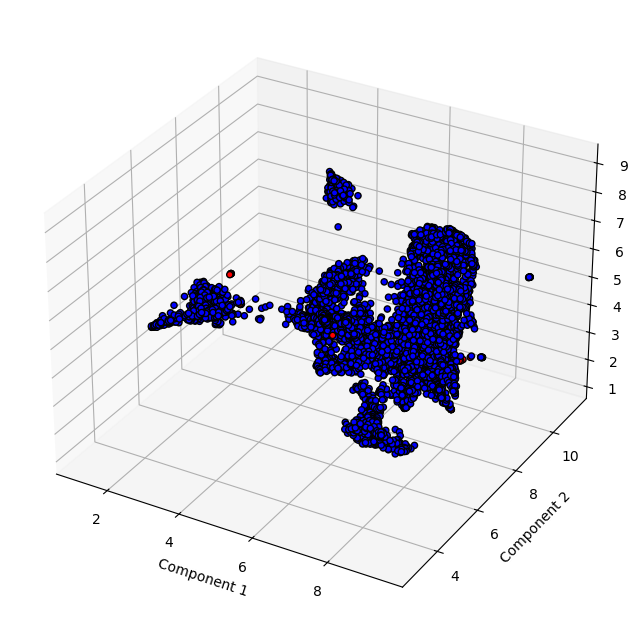

In [58]:
# 2D
plt.scatter(df_unito_umap[:, 0], df_unito_umap[:, 1],
            c=df_outliers['colore'], cmap=plt.cm.bwr, edgecolor='k', alpha=1)

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')

plt.show()

# 3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(df_unito_umap[:, 0],
           df_unito_umap[:, 1],
           df_unito_umap[:, 2],
           c=df_outliers['colore'],
           cmap=plt.cm.bwr,
           edgecolor='k',
           alpha=1)

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')
ax.set_zlabel('Component 3')

plt.show()